# Práctica 4 · Precio de casas en la Gustavo A. Madero (CRISP-DM)
**Minería de Datos · ESCOM-IPN** · Héctor Giovanni García Alvarado

Fases: 1 Negocio · 2 Datos · 3 Preparación · 4 Modelado · 5 Evaluación · 6 Despliegue

**Archivos a subir:** `casas_gam_mercadolibre_*.csv`, `casas_gam_vivanuncios_*.csv` y `casas_gam_lamudi_*.csv` (el que trae la columna `descripcion`).

In [37]:
import re, glob, os, difflib, unicodedata, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import GroupKFold, KFold
from sklearn.neighbors import BallTree
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", message="This pattern is interpreted as a regular expression")
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)


# FASE 1 · Comprensión del negocio
- **Objetivo:** estimar el precio de mercado de una casa en venta en la GAM a partir de sus características. El profesor dará 3–5 casas para comparar con su precio real.
- **Situación:** en México no hay un registro público de precios de compraventa por casa (el valor catastral es reservado y la SHF sólo publica índices agregados). Por eso se usan **anuncios públicos** de portales inmobiliarios, que son precios de oferta. No se guardan datos personales y se respetan los sitios que bloquean la recolección automática.
- **Objetivo de minería:** regresión del logaritmo del **precio por m² construido**. Precio = precio_m2 × m² construidos.
- **Criterios de éxito:** (1) superar a referencias sin ML, (2) error mediano de alrededor de 20 %, (3) un rango que contenga al ~80 % de las casas.


# FASE 2 · Comprensión de los datos
### 2.1 Fuentes evaluadas
| Fuente | Cómo se obtuvo | Decisión |
|---|---|---|
| Mercado Libre | Scraping del listado público (pausas de 2–5 s) |  247 anuncios |
| Vivanuncios | Bloqueó el scraping (403) → páginas guardadas a mano |  495 anuncios |
| Lamudi | Bloquea bots → páginas guardadas a mano |  1,410 anuncios |


Los notebooks de recolección se entregan como anexos.

### 2.2 Carga de datos

In [38]:
CARPETA = "/content" if os.path.exists("/content") else "data"

try:
    from google.colab import files
    import shutil
    for nombre in files.upload():
        if not os.path.exists(os.path.join(CARPETA, nombre)):
            shutil.move(nombre, os.path.join(CARPETA, nombre))
except Exception as e:
    print("Sin subida:", e)


def buscar(patron, columna_requerida=None, obligatorio=True):
    candidatos = sorted(glob.glob(f"{CARPETA}/*{patron}*.csv"))
    if columna_requerida:
        candidatos = [c for c in candidatos if columna_requerida in pd.read_csv(c, nrows=1).columns]
    if not candidatos:
        if obligatorio:
            raise FileNotFoundError(f"No encontré un CSV con '{patron}' en {CARPETA}")
        return None
    print(f"{patron:13s} -> {candidatos[-1].split('/')[-1]}")
    return pd.read_csv(candidatos[-1], low_memory=False)


ml = buscar("mercadolibre")
vv = buscar("vivanuncios")
la = buscar("lamudi", columna_requerida="descripcion")
print(f"\nMercado Libre: {len(ml)} | Vivanuncios: {len(vv)} | Lamudi: {len(la)} | Total: {len(ml) + len(vv) + len(la)}")

Saving CASAS_GAM_1.csv to CASAS_GAM_1.csv
Saving CASAS_GAM_2.csv to CASAS_GAM_2.csv
Saving CASAS_GAM_3.csv to CASAS_GAM_3.csv
mercadolibre  -> casas_gam_mercadolibre_2026-10-21 (1).csv
vivanuncios   -> casas_gam_vivanuncios_2026-10-21.csv
lamudi        -> casas_gam_lamudi_2026-10-22.csv

Mercado Libre: 247 | Vivanuncios: 495 | Lamudi: 1410 | Total: 2152


### 2.3 Descripción

In [39]:
fuentes = {"Mercado Libre": ml, "Vivanuncios": vv, "Lamudi": la}
pct = lambda d, c: round(100 * d[c].notna().mean(), 0) if c in d else 0.0
descripcion_fuentes = pd.DataFrame({
    n: {"anuncios": len(d),
        "precio mediano": f"${d['precio'].median():,.0f}",
        "% con m² construidos": pct(d, "m2_construidos"),
        "% con m² terreno": pct(d, "m2_terreno"),
        "% con antigüedad": pct(d, "antiguedad"),
        "% con coordenadas": pct(d, "lat"),
        "trae descripción": "descripcion" in d}
    for n, d in fuentes.items()}).T
descripcion_fuentes

,anuncios,precio mediano,% con m² construidos,% con m² terreno,% con antigüedad,% con coordenadas,trae descripción
Mercado Libre,247,"$6,600,000",97.0,100.0,94.0,0.0,False
Vivanuncios,495,"$4,500,000",100.0,100.0,0.0,78.0,False
Lamudi,1410,"$780,565",95.0,10.0,0.0,100.0,True


### 2.4 Exploración: precios por fuente, remates y repetidos

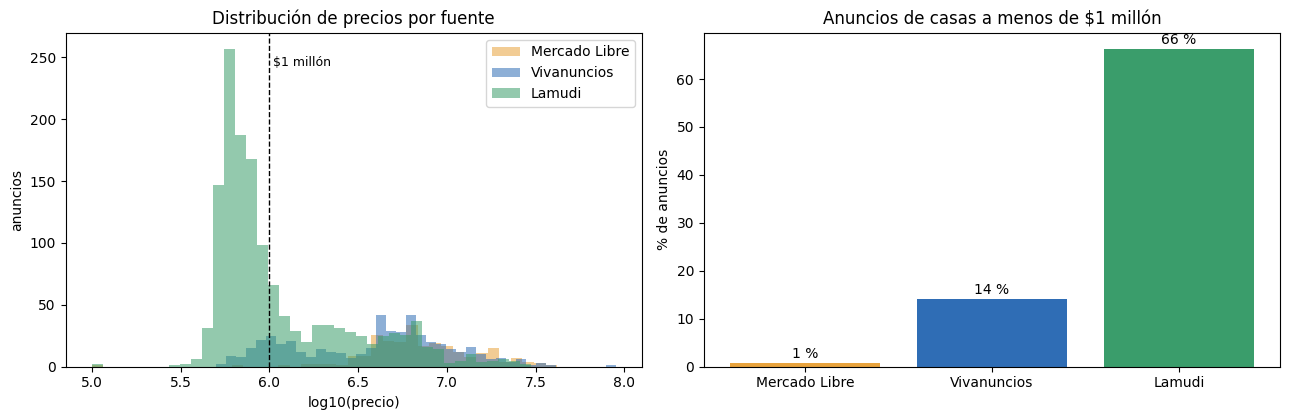

In [40]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for (n, d), color in zip(fuentes.items(), ["#e8a33d", "#2f6db5", "#3a9d6b"]):
    ax[0].hist(np.log10(d["precio"].clip(lower=1e5)), bins=40, alpha=0.55, label=n, color=color)
ax[0].axvline(6, color="k", ls="--", lw=1)
ax[0].text(6.02, ax[0].get_ylim()[1] * 0.9, "$1 millón", fontsize=9)
ax[0].set_xlabel("log10(precio)"); ax[0].set_ylabel("anuncios"); ax[0].legend()
ax[0].set_title("Distribución de precios por fuente")

baratos = {n: 100 * (d["precio"] < 1e6).mean() for n, d in fuentes.items()}
ax[1].bar(baratos.keys(), baratos.values(), color=["#e8a33d", "#2f6db5", "#3a9d6b"])
for i, v in enumerate(baratos.values()):
    ax[1].text(i, v + 1, f"{v:.0f} %", ha="center")
ax[1].set_ylabel("% de anuncios"); ax[1].set_title("Anuncios de casas a menos de $1 millón")
plt.tight_layout(); plt.show()

In [41]:
desc_la = (la["titulo"].fillna("") + " " + la["descripcion"].fillna("")).str.lower()
palabras = {"recuperación bancaria / hipotecaria": r"recuperaci[oó]n", "remate": r"remate",
            "cesión de derechos": r"cesi[oó]n de derechos", "adjudicada": r"adjudicad",
            "no se aceptan créditos": r"no (se )?acepta(n|mos)? cr[eé]dito"}
conteo = pd.Series({k: desc_la.str.contains(p).sum() for k, p in palabras.items()})
alguna = desc_la.str.contains("|".join(palabras.values()))
print("Lamudi: anuncios cuya descripción menciona…")
print(conteo.to_string())
print(f"\nAl menos una de esas palabras: {alguna.sum()} de {len(la)} ({100 * alguna.mean():.0f} %)")
print(f"Precio mediano CON esas palabras: ${la.loc[alguna, 'precio'].median():,.0f}"
      f"  |  SIN ellas: ${la.loc[~alguna, 'precio'].median():,.0f}")

Lamudi: anuncios cuya descripción menciona…
recuperación bancaria / hipotecaria    528
remate                                 344
cesión de derechos                     242
adjudicada                             102
no se aceptan créditos                 274

Al menos una de esas palabras: 964 de 1410 (68 %)
Precio mediano CON esas palabras: $750,000  |  SIN ellas: $1,205,000


In [42]:
def coinciden(a, b):
    m = a.merge(b, on="precio", suffixes=("_a", "_b"))
    m = m[(m["m2_construidos_a"] - m["m2_construidos_b"]).abs() <= 0.05 * m["m2_construidos_a"]]
    return m["id_a"].nunique()

print("Anuncios de Mercado Libre que también están en Vivanuncios (mismo precio y m²):", coinciden(ml, vv), "de", len(ml))
print("Anuncios de Lamudi que también están en Vivanuncios:", coinciden(la, vv), "de", len(la))
print("Anuncios repetidos dentro de Lamudi (mismo precio, m² y colonia):",
      la.duplicated(subset=["precio", "m2_area", "recamaras", "colonia"]).sum())

Anuncios de Mercado Libre que también están en Vivanuncios (mismo precio y m²): 141 de 247
Anuncios de Lamudi que también están en Vivanuncios: 130 de 1410
Anuncios repetidos dentro de Lamudi (mismo precio, m² y colonia): 258


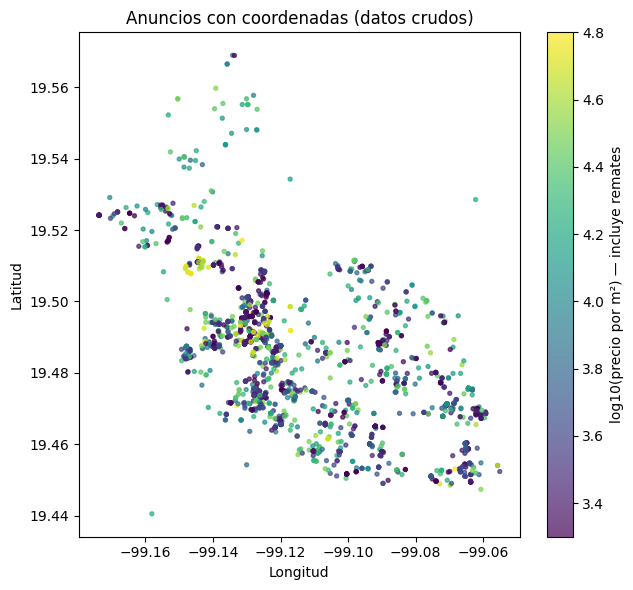

In [43]:
geo = pd.concat([vv[["lat", "lon", "precio", "m2_construidos"]].assign(fuente="Vivanuncios"),
                 la[["lat", "lon", "precio", "m2_construidos"]].assign(fuente="Lamudi")]).dropna()
geo = geo[geo["lat"].between(19.44, 19.60) & geo["lon"].between(-99.20, -99.04)]
fig, ax = plt.subplots(figsize=(6.5, 6))
sc = ax.scatter(geo["lon"], geo["lat"], c=np.log10(geo["precio"] / geo["m2_construidos"]).clip(3.3, 4.8),
                cmap="viridis", s=8, alpha=0.7)
plt.colorbar(sc, label="log10(precio por m²) — incluye remates")
ax.set_title("Anuncios con coordenadas (datos crudos)"); ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud")
plt.tight_layout(); plt.show()

### 2.5 Hallazgos de calidad
1. **Remates:** ~2/3 de Lamudi son remates o cesiones de derechos, con precios muy por debajo del mercado.
2. **Duplicados** dentro de cada portal y entre portales.
3. **Ubicaciones falsas:** desarrollos de Pachuca anunciados con colonias de la GAM.
4. **Errores de captura:** superficies imposibles, año de construcción como antigüedad.
5. **Colonias escritas de varias formas.**
6. **Datos incompletos:** Mercado Libre sin coordenadas; Lamudi casi sin m² de superficie.
7. **Cobertura desigual:** muchos anuncios en Lindavista, pocos en colonias populares.

---
# FASE 3 · Preparación de los datos
Formato → Limpieza → Integración → Selección → Construcción.

### 3.1 Formato
Las 3 fuentes se llevan a las mismas columnas. Vivanuncios: título desde la URL. Lamudi: m² construidos desde la descripción o la tarjeta. Mercado Libre: el año de construcción capturado como antigüedad se convierte a años.

In [44]:
COLUMNAS = ["fuente", "id_original", "url", "titulo", "texto", "precio", "moneda",
            "m2_construidos", "m2_terreno", "recamaras", "banos", "estacionamientos",
            "antiguedad", "colonia_original", "lat", "lon", "coord_exacta", "fecha_captura"]


def de_mercadolibre(d):
    o = pd.DataFrame({
        "fuente": "Mercado Libre", "id_original": d["id"], "url": d["url"], "titulo": d["titulo"],
        "texto": d["titulo"], "precio": d["precio"], "moneda": d["moneda"].replace({"$": "MXN"}),
        "m2_construidos": d["m2_construidos"], "m2_terreno": d.get("m2_terreno"),
        "recamaras": d["recamaras"], "banos": d["banos"], "estacionamientos": d.get("estacionamientos"),
        "antiguedad": d.get("antiguedad"), "colonia_original": d["colonia"],
        "lat": np.nan, "lon": np.nan, "coord_exacta": False, "fecha_captura": d["fecha_captura"]})
    # Algunos anunciantes escriben el AÑO de construcción en lugar de la antigüedad (ej. 1985)
    anio = o["antiguedad"].between(1900, 2026)
    o.loc[anio, "antiguedad"] = 2026 - o.loc[anio, "antiguedad"]
    o.loc[o["antiguedad"] > 120, "antiguedad"] = np.nan
    return o[COLUMNAS]


def de_vivanuncios(d):
    titulo = (d["url"].str.extract(r"/a-venta-[^/]+/[^/]+/([^/]+)/\d+")[0]
              .str.replace("-", " ").str.replace(" m sup2 ", " m² ").str.strip())
    o = pd.DataFrame({
        "fuente": "Vivanuncios", "id_original": d["id"].astype(str), "url": d["url"], "titulo": titulo,
        "texto": titulo, "precio": d["precio"], "moneda": d["moneda"],
        "m2_construidos": d["m2_construidos"], "m2_terreno": d["m2_terreno"],
        "recamaras": d["recamaras"], "banos": d["banos"], "estacionamientos": d["estacionamientos"],
        "antiguedad": np.nan, "colonia_original": d["colonia"],
        "lat": d["lat"], "lon": d["lon"], "coord_exacta": d["lat"].notna(), "fecha_captura": d["fecha_captura"]})
    return o[COLUMNAS]


def de_lamudi(d):
    o = pd.DataFrame({
        "fuente": "Lamudi", "id_original": d["id"], "url": d["url"], "titulo": d["titulo"],
        "texto": d["titulo"].fillna("") + " || " + d["descripcion"].fillna(""),
        "precio": d["precio"], "moneda": d["moneda"],
        "m2_construidos": d["m2_construidos_desc"].fillna(d["m2_area"]), "m2_terreno": d["m2_terreno_desc"],
        "recamaras": d["recamaras"], "banos": d["banos"], "estacionamientos": d["estacionamientos"],
        "antiguedad": np.nan, "colonia_original": d["colonia"],
        "lat": d["lat"], "lon": d["lon"], "coord_exacta": d["ubicacion_exacta"].fillna(False).astype(bool),
        "fecha_captura": d["fecha_captura"]})
    return o[COLUMNAS]


df = pd.concat([de_mercadolibre(ml), de_vivanuncios(vv), de_lamudi(la)], ignore_index=True)
df.insert(0, "fila", range(len(df)))
print(df.shape)
df.groupby("fuente")[["precio", "m2_construidos", "m2_terreno", "lat"]].count()

(2152, 19)


,precio,m2_construidos,m2_terreno,lat
fuente,,,,
Lamudi,1410,1338,144,1410
Mercado Libre,247,240,247,0
Vivanuncios,495,495,495,386


### 3.2 Limpieza
**Colonias:** se unifican nombres escritos de distintas formas (acentos, "Secc"/"Sección", "Colonia …"). Lo que no es colonia se deja vacío.

In [45]:
NO_SON_COLONIA = {"gustavo a madero", "gam cdmx", "mexico", "cdmx", "ciudad de mexico", "distrito federal"}
ORDINALES = {"1a": "i", "2a": "ii", "3a": "iii", "4a": "iv", "5a": "v", "6a": "vi", "7a": "vii",
             "1": "i", "2": "ii", "3": "iii", "4": "iv", "5": "v", "6": "vi", "7": "vii"}


def sin_acentos(s):
    return "".join(c for c in unicodedata.normalize("NFD", s) if unicodedata.category(c) != "Mn")


def llave_colonia(nombre):
    if not isinstance(nombre, str) or not nombre.strip():
        return None
    s = re.sub(r"(?<=[a-z])A(?=[a-z])", "á", nombre)          # 'HernAndez' -> 'Hernández'
    s = sin_acentos(s.lower())
    s = re.sub(r"^colonia\s+", "", s)
    s = re.sub(r"[\.,]", " ", s)
    s = re.sub(r"\bsecc(ion)?\b", "seccion", s)
    s = re.sub(r"\b(\d)a?\s+seccion\b", lambda m: ORDINALES[m.group(1)] + " seccion", s)
    s = re.sub(r"\bex\s+escuela\b", "exescuela", s)
    s = re.sub(r"\bgertrudiz\b", "gertrudis", s)
    s = re.sub(r"^casas aleman amp$", "ampliacion casas aleman", s)
    s = re.sub(r"\s+", " ", s).strip()
    if s in NO_SON_COLONIA or "gustavo" in s and "villa" not in s or s.startswith(("venta ", "avenida ")):
        return None
    return s


df["colonia_llave"] = df["colonia_original"].map(llave_colonia)

# Nombre "bonito": la forma más común (con acentos) de cada llave
def nombre_bonito(variantes):
    variantes = [re.sub(r"(?<=[a-z])A(?=[a-z])", "á", re.sub(r"^Colonia\s+", "", v)) for v in variantes]
    conteo = Counter(variantes)
    return max(conteo, key=lambda v: (conteo[v], sum(ch in "áéíóúÁÉÍÓÚ" for ch in v), " de " in v))

nombres = df.dropna(subset=["colonia_llave"]).groupby("colonia_llave")["colonia_original"].agg(nombre_bonito)
nombres = nombres.str.replace(r"\bSecc\.?$", "Sección", regex=True)
df["colonia"] = df["colonia_llave"].map(nombres)

print("Colonias distintas: antes", df["colonia_original"].nunique(), "-> después", df["colonia"].nunique())
print("Sin colonia válida:", df["colonia"].isna().sum())

Colonias distintas: antes 188 -> después 138
Sin colonia válida: 36


**Coordenadas:** se anulan las que caen fuera de la GAM.

In [46]:
DENTRO_GAM = df["lat"].between(19.44, 19.60) & df["lon"].between(-99.20, -99.04)
fuera = df["lat"].notna() & ~DENTRO_GAM
print("Coordenadas fuera de la GAM:", fuera.sum())
df.loc[fuera, ["lat", "lon"]] = np.nan
df.loc[fuera, "coord_exacta"] = False

Coordenadas fuera de la GAM: 1


### 3.3 Integración
Dos anuncios son la **misma casa** si coinciden en precio (±1 %), m² construidos (±5 %) y colonia (o están a menos de 600 m). Se agrupan y queda un solo registro con el dato más completo de cada fuente.

In [47]:
def distancia_m(lat1, lon1, lat2, lon2):
    if any(pd.isna(x) for x in (lat1, lon1, lat2, lon2)):
        return np.nan
    p = np.pi / 180
    a = (np.sin((lat2 - lat1) * p / 2) ** 2
         + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2)
    return 12_742_000 * np.arcsin(np.sqrt(a))


def misma_casa(a, b):
    if abs(a.precio - b.precio) > 0.01 * max(a.precio, b.precio):
        return False
    if pd.notna(a.m2_construidos) and pd.notna(b.m2_construidos):
        if abs(a.m2_construidos - b.m2_construidos) > 0.05 * max(a.m2_construidos, b.m2_construidos):
            return False
    elif pd.isna(a.m2_construidos) and pd.isna(b.m2_construidos):
        if a.recamaras != b.recamaras:
            return False
    else:
        return False
    d = distancia_m(a.lat, a.lon, b.lat, b.lon)
    if pd.notna(d):
        return d <= 600
    if isinstance(a.colonia_llave, str) and isinstance(b.colonia_llave, str):
        return a.colonia_llave == b.colonia_llave
    return True


padre = list(range(len(df)))
def raiz(i):
    while padre[i] != i:
        padre[i] = padre[padre[i]]
        i = padre[i]
    return i

orden = df.dropna(subset=["precio"]).sort_values("precio")
filas = list(orden.itertuples())
for i, a in enumerate(filas):
    for b in filas[i + 1:]:
        if b.precio > a.precio * 1.01:
            break
        if misma_casa(a, b):
            padre[raiz(a.fila)] = raiz(b.fila)

df["grupo"] = [raiz(i) for i in range(len(df))]
tam = df.groupby("grupo")["fila"].transform("size")
print("Anuncios:", len(df), "| casas distintas:", df["grupo"].nunique(),
      "| anuncios repetidos:", len(df) - df["grupo"].nunique())
print("\nCasas que aparecen en varios portales:")
print(df.groupby("grupo")["fuente"].agg(lambda s: " + ".join(sorted(set(s))))
        .loc[lambda s: s.str.contains("\\+")].value_counts())

Anuncios: 2152 | casas distintas: 1556 | anuncios repetidos: 596

Casas que aparecen en varios portales:
fuente
Mercado Libre + Vivanuncios             71
Lamudi + Mercado Libre + Vivanuncios    32
Lamudi + Vivanuncios                    30
Lamudi + Mercado Libre                  19
Name: count, dtype: int64


**Señales** (se heredan a todo el grupo de la casa):
- **Remate:** remate, recuperación bancaria, cesión de derechos, adjudicada, sólo contado, no se aceptan créditos… No es precio de mercado.
- **Tipo:** casa, departamento o edificio/varias viviendas (todos se conservan).
- **No es vivienda en venta:** renta, oficinas, locales, terrenos.
- **Ubicación falsa:** desarrollos de otro municipio y anuncios "plantilla" (mismo texto y precio en 3+ colonias).

In [48]:
REMATE = (r"remate|recuperaci[oó]n|cesi[oó]n de derechos|adjudicad|litigio|juicio"
          r"|cartera (vencida|hipotecaria|propia|bancaria)"
          r"|no (se )?acepta(n|mos)? (ning[uú]n )?cr[eé]ditos?|sin cr[eé]ditos?|no aplica(n)? cr[eé]ditos?"
          r"|s[oó]lo (pago )?(de )?contado|[uú]nicamente (pago )?(de )?contado|(dos|2) exhibiciones"
          r"|(s[oó]lo|[uú]nicamente|exclusivamente)[^.]{0,25}recursos propios|\*recursos propios\*"
          r"|por debajo de(l)? (su )?(valor|costo|precio) comercial|debajo de su valor"
          r"|no se puede (ver|visitar|ingresar|conocer)|sin acceso (al|a la) (inmueble|propiedad)"
          r"|no (hay|se dan|se permiten) visitas")

DEPARTAMENTO = r"^\W*((bonito|excelente|amplio|hermoso)\s+)?(departamento|depto|dpto)\b"
VARIAS_VIVIENDAS = (r"\bedificio\b|\b(con|de) \d+ (departamentos|deptos|depas|viviendas)"
                    r"|mini ?departamen|casas? (de )?productos?|\b\d+ casas en")

NO_CASA = (r"\ben renta\b|\b(con|de) \d+ locales"
           r"|para oficinas|consultorios|restaurante|bodega industrial|para bodega"
           r"|con locales comerciales|locales comerciales ?en planta baja"
           r"|^\W*terreno\b|\bcomo terreno\b|precio de terreno|terreno-casa")

FUERA_GAM = (r"\ben pachuca\b|sur de pachuca|pachuca,? (hgo|hidalgo)|comenzar en pachuca"
             r"|cerca de (la )?cdmx|a (solo )?\d+ minutos de (la )?(cdmx|ciudad de m[eé]xico)")

texto = df["texto"].fillna("").str.lower().str.replace(r"\s+", " ", regex=True)
df["señal_remate"] = texto.str.contains(REMATE, regex=True)
titulo_min = df["titulo"].fillna("").str.lower()
df["señal_no_casa"] = titulo_min.str.contains(NO_CASA, regex=True)
df["tipo"] = np.select([titulo_min.str.contains(VARIAS_VIVIENDAS, regex=True),
                        titulo_min.str.contains(DEPARTAMENTO, regex=True)],
                       ["edificio / varias viviendas", "departamento"], "casa")
print("Anuncios con señal de remate:", df["señal_remate"].sum())
# Anuncio "plantilla": la misma descripción y el mismo precio publicados en muchas colonias distintas
descripcion = texto.str.split(r" \|\| ", n=1, regex=True).str[1].fillna("").str[:200]
plantilla = (df.assign(_d=descripcion)[descripcion.str.len() > 80]
               .groupby(["_d", "precio"]).filter(lambda g: len(g) >= 5 and g["colonia_llave"].nunique() >= 3).index)
df["señal_fuera_gam"] = texto.str.contains(FUERA_GAM, regex=True) | df.index.isin(plantilla)
print("Anuncios por tipo:", df["tipo"].value_counts().to_dict())
print("Anuncios que no son vivienda en venta:", df["señal_no_casa"].sum())
print("Anuncios plantilla (mismo texto y precio en 3+ colonias):", len(plantilla))
print("Anuncios con ubicación falsa (otro municipio o plantilla):", df["señal_fuera_gam"].sum())

Anuncios con señal de remate: 1083
Anuncios por tipo: {'casa': 2122, 'edificio / varias viviendas': 25, 'departamento': 5}
Anuncios que no son vivienda en venta: 23
Anuncios plantilla (mismo texto y precio en 3+ colonias): 46
Anuncios con ubicación falsa (otro municipio o plantilla): 55


**Fusión:** un registro por casa.

In [49]:
PRIORIDAD = {"Vivanuncios": 0, "Lamudi": 1, "Mercado Libre": 2}
df["_prio"] = df["fuente"].map(PRIORIDAD) + (~df["coord_exacta"]).astype(int) * 0.5


def primero(serie):
    s = serie.dropna()
    return s.iloc[0] if len(s) else np.nan


def fusionar(g):
    g = g.sort_values("_prio")
    con_coord = g.dropna(subset=["lat"])
    con_coord = con_coord.sort_values(["coord_exacta", "_prio"], ascending=[False, True])
    return pd.Series({
        "fuentes": " + ".join(sorted(set(g["fuente"]))),
        "n_anuncios": len(g),
        "url": g["url"].iloc[0],
        "titulo": primero(g["titulo"]),
        "precio": g["precio"].iloc[0],
        "moneda": g["moneda"].iloc[0],
        "m2_construidos": primero(g["m2_construidos"]),
        "m2_terreno": primero(g["m2_terreno"]),
        "recamaras": primero(g["recamaras"]),
        "banos": primero(g["banos"]),
        "estacionamientos": primero(g["estacionamientos"]),
        "antiguedad": primero(g["antiguedad"]),
        "colonia": primero(g["colonia"]),
        "lat": con_coord["lat"].iloc[0] if len(con_coord) else np.nan,
        "lon": con_coord["lon"].iloc[0] if len(con_coord) else np.nan,
        "coord_exacta": bool(con_coord["coord_exacta"].iloc[0]) if len(con_coord) else False,
        "señal_remate": g["señal_remate"].any(),
        "señal_no_casa": g["señal_no_casa"].any(),
        "tipo": ("edificio / varias viviendas" if (g["tipo"] == "edificio / varias viviendas").any()
                 else "departamento" if (g["tipo"] == "departamento").mean() > 0.5 else "casa"),
        "señal_fuera_gam": g["señal_fuera_gam"].any(),
        "ids_originales": " | ".join(g["id_original"].astype(str)),
        "fecha_captura": g["fecha_captura"].max(),
    })


casas = df.groupby("grupo").apply(fusionar, include_groups=False).reset_index(drop=True)
casas.insert(0, "id_casa", [f"GAM{i:04d}" for i in range(1, len(casas) + 1)])
print("Casas distintas:", len(casas))
casas["fuentes"].value_counts()

Casas distintas: 1556


,count
fuentes,
Lamudi,975
Vivanuncios,333
Mercado Libre,96
Mercado Libre + Vivanuncios,71
Lamudi + Mercado Libre + Vivanuncios,32
Lamudi + Vivanuncios,30
Lamudi + Mercado Libre,19


### 3.4 Selección
| # | Se excluye | Motivo |
|---|---|---|
| 1 | Precio no en pesos | No mezclar monedas |
| 2 | Ubicación falsa | No está en la GAM |
| 3 | No es vivienda en venta | Rentas, oficinas, locales, terrenos |
| 4 | Remate / cesión de derechos | No es precio de mercado |
| 5 | Sin m² construidos | No se puede calcular el precio por m² |
| 6 | Superficie imposible | < 40 o > 1,500 m² construidos, o > 2,000 m² de superficie |
| 7 | Precio por m² < $8,000 | Remate no declarado o error |
| 8 | Precio por m² > $80,000 | Error de captura |

Las casas con muchas recámaras se revisaron y se conservan: son casas grandes reales.

In [50]:
casas["precio_m2"] = casas["precio"] / casas["m2_construidos"]

REGLAS = [
    ("1. Precio no en pesos",               casas["moneda"] != "MXN"),
    ("2. Ubicación falsa",                  casas["señal_fuera_gam"]),
    ("3. No es vivienda en venta",          casas["señal_no_casa"]),
    ("4. Remate / cesión de derechos",      casas["señal_remate"]),
    ("5. Sin m² construidos",               casas["m2_construidos"].isna()),
    ("6. Superficie imposible",             (casas["m2_construidos"] < 40) | (casas["m2_construidos"] > 1500)
                                            | (casas["m2_terreno"] > 2000)),
    ("7. Precio por m² < $8,000",           casas["precio_m2"] < 8_000),
    ("8. Precio por m² > $80,000",          casas["precio_m2"] > 80_000),
]

casas["motivo_exclusion"] = None
for motivo, mascara in REGLAS:
    nuevas = mascara.fillna(False) & casas["motivo_exclusion"].isna()
    casas.loc[nuevas, "motivo_exclusion"] = motivo

resumen = casas["motivo_exclusion"].fillna("✔ Se queda").value_counts().sort_index()
print(resumen.to_string())
print(f"\nSe quedan {casas['motivo_exclusion'].isna().sum()} de {len(casas)} casas distintas")

motivo_exclusion
2. Ubicación falsa                 44
3. No es vivienda en venta         18
4. Remate / cesión de derechos    781
5. Sin m² construidos              16
6. Superficie imposible             7
7. Precio por m² < $8,000         183
8. Precio por m² > $80,000          1
✔ Se queda                        506

Se quedan 506 de 1556 casas distintas


Ejemplos de cada regla:

In [51]:
for motivo, _ in REGLAS:
    muestra = casas[casas["motivo_exclusion"] == motivo]
    if len(muestra):
        print(f"\n{motivo}  ({len(muestra)})")
        for _, r in muestra.sample(min(4, len(muestra)), random_state=0).iterrows():
            print(f"   ${r.precio:>12,.0f} | {r.m2_construidos!s:>6} m² | {r.colonia} | {str(r.titulo)[:70]}")


2. Ubicación falsa  (44)
   $     490,000 |  190.0 m² | Villa de Aragón | Casa en Venta en Villa de Aragón
   $     990,000 |  243.0 m² | Residencial Zacatenco | Casa en Venta en Residencial Zacatenco
   $     490,000 |  251.0 m² | San Juan de Aragón VII Sección | Casa en Venta en San Juan de Aragón VII Sección
   $     990,000 |  180.0 m² | Industrial | Casa en Venta en Industrial

3. No es vivienda en venta  (18)
   $      60,000 |  265.0 m² | Lindavista Norte | Casa En Renta Torres Lindavista
   $  30,000,000 | 1320.0 m² | Santa Isabel Tola | Venta De Salon De Eventos Con Restaurante Y Un Loft
   $   6,500,000 |  386.0 m² | Industrial | inmueble en venta con locales comercialesen planta baja colonia indust
   $   3,200,000 |  126.0 m² | Zona Escolar | venta de casa a precio de terreno en zona escolar gam

4. Remate / cesión de derechos  (781)
   $   5,350,000 |  300.0 m² | Estrella | Casa en Venta en Estrella
   $     869,500 |  250.0 m² | Guadalupe Tepeyac | Casa en Venta en Guada

In [52]:
limpio = casas[casas["motivo_exclusion"].isna()].copy()
excluidas = casas[casas["motivo_exclusion"].notna()].copy()
print("Casas limpias:", len(limpio))

Casas limpias: 506


### 3.5 Construcción
**Colonia faltante:** la más común entre las 5 casas más cercanas.

In [53]:
ref = limpio.dropna(subset=["colonia", "lat"])
sin_col = limpio["colonia"].isna() & limpio["lat"].notna()
for i, r in limpio[sin_col].iterrows():
    d = np.hypot(ref["lat"] - r.lat, (ref["lon"] - r.lon) * np.cos(np.radians(r.lat)))
    limpio.loc[i, "colonia"] = ref.loc[d.nsmallest(5).index, "colonia"].mode().iloc[0]
limpio["colonia_origen"] = np.where(sin_col, "estimada (vecinos)", "anuncio")
limpio.loc[limpio["colonia"].isna(), "colonia_origen"] = None
print("Colonias estimadas por vecinos:", sin_col.sum(), "| siguen sin colonia:", limpio["colonia"].isna().sum())

Colonias estimadas por vecinos: 11 | siguen sin colonia: 3


**Coordenadas faltantes:** centro de su colonia (queda marcado en `coord_origen`).

In [54]:
# Se usan todas las coordenadas exactas recolectadas (incluso de casas excluidas): la ubicación sigue siendo válida
centros = df[df["coord_exacta"] & df["colonia"].notna()].groupby("colonia")[["lat", "lon"]].median()
limpio["coord_origen"] = np.where(limpio["lat"].notna(),
                                  np.where(limpio["coord_exacta"], "anuncio (exacta)", "anuncio (aproximada)"),
                                  None)
falta = limpio["lat"].isna() & limpio["colonia"].isin(centros.index)
limpio.loc[falta, "lat"] = limpio.loc[falta, "colonia"].map(centros["lat"])
limpio.loc[falta, "lon"] = limpio.loc[falta, "colonia"].map(centros["lon"])
limpio.loc[falta, "coord_origen"] = "centro de la colonia"
print(limpio["coord_origen"].value_counts(dropna=False).to_string())

coord_origen
anuncio (exacta)        318
centro de la colonia    133
anuncio (aproximada)     31
None                     24


**Variable objetivo:** `precio_m2` y su logaritmo.

In [55]:
limpio["precio_m2"] = (limpio["precio"] / limpio["m2_construidos"]).round(2)
limpio["log_precio_m2"] = np.log(limpio["precio_m2"]).round(5)

print(limpio[["precio", "m2_construidos", "m2_terreno", "recamaras", "banos",
              "estacionamientos", "antiguedad", "precio_m2"]].describe().round(1).T)
print("\nDatos disponibles (de", len(limpio), "casas):")
print(limpio[["m2_terreno", "recamaras", "banos", "estacionamientos", "antiguedad", "colonia", "lat"]]
      .notna().sum().to_string())

                  count       mean        std       min        25%        50%        75%         max
precio            506.0  7696146.7  6144345.3  624000.0  4150000.0  5950000.0  8897500.0  42000000.0
m2_construidos    506.0      288.7      172.0      42.0      180.0      249.0      367.8      1390.0
m2_terreno        458.0      225.3      154.5      30.0      144.0      175.0      246.5      1470.0
recamaras         500.0        4.3        2.0       1.0        3.0        4.0        5.0        22.0
banos             502.0        2.9        1.6       1.0        2.0        3.0        4.0        12.0
estacionamientos  472.0        2.5        1.8       0.0        1.0        2.0        3.0        12.0
antiguedad        181.0       31.8       19.5       0.0       17.0       35.0       46.0        75.0
precio_m2         506.0    26509.6    12344.2    8333.3    17918.8    23938.2    32653.3     75000.0

Datos disponibles (de 506 casas):
m2_terreno          458
recamaras           500
banos   

In [56]:
print("Casas por colonia (top 20):")
print(limpio["colonia"].value_counts().head(20).to_string())
print("\nColonias con 1-2 casas:", (limpio["colonia"].value_counts() <= 2).sum(),
      "de", limpio["colonia"].nunique())
print("\nPrecio por m² mediano por colonia (con al menos 8 casas):")
print(limpio.groupby("colonia")["precio_m2"].agg(["count", "median"])
      .query("count >= 8").sort_values("median", ascending=False).round(0).to_string())

Casas por colonia (top 20):
colonia
Lindavista Norte                  54
Industrial                        25
Lindavista                        23
Lindavista Sur                    23
Torres Lindavista                 19
Tepeyac Insurgentes               19
Estrella                          14
San Felipe de Jesús               14
San Juan de Aragón VI Sección     11
San Juan de Aragón III Sección     9
La Joya                            9
Valle del Tepeyac                  9
San Juan de Aragón I Sección       9
Guadalupe Tepeyac                  9
San Juan de Aragón                 9
Acueducto de Guadalupe             9
Residencial Zacatenco              8
Ampliación Casas Alemán            8
Vallejo                            7
San Bartolo Atepehuacan            6

Colonias con 1-2 casas: 59 de 114

Precio por m² mediano por colonia (con al menos 8 casas):
                                count   median
colonia                                       
Torres Lindavista                  1

### 3.6 Guardar

In [57]:
COLS_FINALES = ["id_casa", "tipo", "fuentes", "n_anuncios", "precio", "precio_m2", "log_precio_m2",
                "m2_construidos", "m2_terreno", "recamaras", "banos", "estacionamientos", "antiguedad",
                "colonia", "colonia_origen", "lat", "lon", "coord_origen", "titulo", "url",
                "ids_originales", "fecha_captura"]
limpio[COLS_FINALES].to_csv("casas_gam_limpio.csv", index=False, encoding="utf-8-sig")

excluidas[["id_casa", "motivo_exclusion", "tipo", "fuentes", "precio", "precio_m2", "m2_construidos", "m2_terreno",
           "recamaras", "banos", "colonia", "titulo", "url"]].to_csv(
    "casas_gam_excluidas.csv", index=False, encoding="utf-8-sig")

resumen_flujo = pd.DataFrame({
    "paso": ["Anuncios recolectados", "Casas distintas (sin repetidos)"]
            + [f"Excluidas: {m}" for m, _ in REGLAS] + ["Dataset final"],
    "casas": [len(df), len(casas)]
             + [int((casas["motivo_exclusion"] == m).sum()) for m, _ in REGLAS] + [len(limpio)],
})
resumen_flujo.to_csv("resumen_limpieza.csv", index=False, encoding="utf-8-sig")
print(resumen_flujo.to_string(index=False))

                                     paso  casas
                    Anuncios recolectados   2152
          Casas distintas (sin repetidos)   1556
         Excluidas: 1. Precio no en pesos      0
            Excluidas: 2. Ubicación falsa     44
    Excluidas: 3. No es vivienda en venta     18
Excluidas: 4. Remate / cesión de derechos    781
         Excluidas: 5. Sin m² construidos     16
       Excluidas: 6. Superficie imposible      7
     Excluidas: 7. Precio por m² < $8,000    183
    Excluidas: 8. Precio por m² > $80,000      1
                            Dataset final    506



# FASE 4 · Modelado
Además de las características de la casa, se usan **comparables** (como un valuador): el precio por m² suavizado de la colonia y el de las 10 casas más cercanas. Se calculan **dentro** de la validación cruzada, nunca con la casa evaluada, para evitar fuga de datos.

In [58]:
datos = limpio[COLS_FINALES].reset_index(drop=True)
print("Casas para modelar:", len(datos))

Casas para modelar: 506


### 4.1 Variables
- **Del anuncio:** m² de superficie (terreno), m² construidos, recámaras, baños, estacionamientos, antigüedad, coordenadas y tipo.
- **Calculadas:** superficie entre construcción, m² por recámara.
- **Comparables:** precio/m² de la colonia, precio/m² de los vecinos, distancia a los vecinos y casas en la colonia.

In [59]:
df = datos.copy()
df["terreno_entre_construccion"] = df["m2_terreno"] / df["m2_construidos"]
df["m2_por_recamara"] = df["m2_construidos"] / df["recamaras"].replace(0, np.nan)

NUMERICAS = ["m2_construidos", "m2_terreno", "recamaras", "banos", "estacionamientos", "antiguedad",
             "lat", "lon", "terreno_entre_construccion", "m2_por_recamara"]
CATEGORICAS = ["tipo"]
COMPARABLES_IN = ["colonia", "lat", "lon"]

X = df[NUMERICAS + CATEGORICAS + ["colonia"]]
y = df["log_precio_m2"].values           # objetivo: log del precio por m²
m2 = df["m2_construidos"].values
precio_real = df["precio"].values
print("Casas:", len(X))
print("Faltantes por variable:")
print(X.isna().sum()[lambda s: s > 0].to_string())

Casas: 506
Faltantes por variable:
m2_terreno                     48
recamaras                       6
banos                           4
estacionamientos               34
antiguedad                    325
lat                            24
lon                            24
terreno_entre_construccion     48
m2_por_recamara                 6
colonia                         3


### 4.2 Comparables sin fuga de datos
Transformador de scikit-learn: colonia suavizada (m = 5), promedio de los 10 vecinos más cercanos (distancia haversine) y *cross-fitting* en entrenamiento.

In [60]:
def llave(s):
    if not isinstance(s, str):
        return None
    s = "".join(c for c in unicodedata.normalize("NFD", s.lower()) if unicodedata.category(c) != "Mn")
    return " ".join(s.replace(".", " ").split())


class Comparables(BaseEstimator, TransformerMixin):
    def __init__(self, k=10, m=5, n_splits=5, random_state=0):
        self.k = k
        self.m = m
        self.n_splits = n_splits
        self.random_state = random_state

    # --- guarda la "base de comparables" ---
    def fit(self, X, y):
        X = pd.DataFrame(X, columns=COMPARABLES_IN)
        self.col_ = X["colonia"].map(llave).values
        self.coords_ = X[["lat", "lon"]].values.astype(float)
        self.y_ = np.asarray(y, dtype=float)
        self.media_ = self.y_.mean()
        return self

    def _codificar(self, Xn, col_tr, coords_tr, y_tr):
        media = y_tr.mean()
        tabla = pd.DataFrame({"c": col_tr, "y": y_tr}).dropna().groupby("c")["y"].agg(["sum", "count"])
        col = pd.Series(Xn["colonia"].map(llave).values)
        suma = col.map(tabla["sum"]).fillna(0).values
        n = col.map(tabla["count"]).fillna(0).values
        colonia_pm2 = (suma + self.m * media) / (n + self.m)

        vec_pm2 = np.full(len(Xn), np.nan)
        vec_dist = np.full(len(Xn), np.nan)
        ok_tr = ~np.isnan(coords_tr).any(axis=1)
        q = Xn[["lat", "lon"]].values.astype(float)
        ok_q = ~np.isnan(q).any(axis=1)
        if ok_tr.sum() >= self.k and ok_q.any():
            arbol = BallTree(np.radians(coords_tr[ok_tr]), metric="haversine")
            dist, idx = arbol.query(np.radians(q[ok_q]), k=self.k)
            vec_pm2[ok_q] = y_tr[ok_tr][idx].mean(axis=1)
            vec_dist[ok_q] = dist.mean(axis=1) * 6371
        return np.column_stack([colonia_pm2, n, vec_pm2, vec_dist])

    def transform(self, X):
        Xn = pd.DataFrame(X, columns=COMPARABLES_IN).reset_index(drop=True)
        return self._codificar(Xn, self.col_, self.coords_, self.y_)

    # --- en entrenamiento: cada casa se codifica SIN sí misma (cross-fitting) ---
    def fit_transform(self, X, y):
        self.fit(X, y)
        Xn = pd.DataFrame(X, columns=COMPARABLES_IN).reset_index(drop=True)
        salida = np.zeros((len(Xn), 4))
        kf = KFold(self.n_splits, shuffle=True, random_state=self.random_state)
        for tr, va in kf.split(Xn):
            salida[va] = self._codificar(Xn.iloc[va], self.col_[tr], self.coords_[tr], self.y_[tr])
        return salida

    def get_feature_names_out(self, input_features=None):
        return np.array(["colonia_precio_m2", "casas_en_colonia", "vecinos_precio_m2", "vecinos_distancia_km"])

### 4.3 Técnicas
Referencias sin ML: mediana de la GAM y mediana de la colonia. Modelos: Ridge, Random Forest y Gradient Boosting, cada uno con y sin comparables.

In [61]:
def preprocesador(con_comparables=True, escalar=False):
    num = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()) if escalar else "passthrough"
    partes = [("num", num, NUMERICAS),
              ("tipo", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAS)]
    if con_comparables:
        comp = make_pipeline(Comparables(), SimpleImputer(strategy="median"), StandardScaler()) if escalar else Comparables()
        partes.append(("comparables", comp, COMPARABLES_IN))
    return ColumnTransformer(partes)


def modelos(con_comparables=True):
    return {
        "Ridge": Pipeline([("prep", preprocesador(con_comparables, escalar=True)),
                           ("m", RidgeCV(alphas=np.logspace(-2, 3, 20)))]),
        "Random Forest": Pipeline([("prep", preprocesador(con_comparables)),
                                   ("m", RandomForestRegressor(n_estimators=500, min_samples_leaf=3,
                                                               max_features=0.5, random_state=0, n_jobs=-1))]),
        "Gradient Boosting": Pipeline([("prep", preprocesador(con_comparables)),
                                       ("m", HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300,
                                                                           max_leaf_nodes=15, min_samples_leaf=10,
                                                                           l2_regularization=1.0, random_state=0))]),
    }

### 4.4 Diseño de prueba
K-Fold de 5 particiones × 3 semillas. Métricas sobre el precio total: MAPE, error mediano, % dentro de ±15 % y ±25 %, MAE y R².

In [62]:
def metricas(precio_real, precio_pred, y_log, y_log_pred):
    err = np.abs(precio_pred - precio_real) / precio_real
    ss = ((y_log - y_log_pred) ** 2).sum() / ((y_log - y_log.mean()) ** 2).sum()
    return {"MAPE %": 100 * err.mean(), "Error mediano %": 100 * np.median(err),
            "Dentro ±15 %": 100 * (err <= 0.15).mean(), "Dentro ±25 %": 100 * (err <= 0.25).mean(),
            "MAE (millones)": np.abs(precio_pred - precio_real).mean() / 1e6, "R² log(p/m²)": 1 - ss}


def predecir_oof(modelo, X, y, cv, grupos=None):
    """Predicción fuera de muestra: cada casa la predice un modelo entrenado sin ella."""
    pred = np.zeros(len(y))
    for tr, te in cv.split(X, y, grupos):
        if modelo == "mediana GAM":
            pred[te] = np.median(y[tr])
        elif modelo == "mediana colonia":
            col = X["colonia"].map(llave)
            tabla = pd.Series(y[tr]).groupby(col.iloc[tr].values).median()
            pred[te] = col.iloc[te].map(tabla).fillna(np.median(y[tr])).values
        else:
            m = clone(modelo).fit(X.iloc[tr], y[tr])
            pred[te] = m.predict(X.iloc[te])
    return pred


SEMILLAS = [0, 1, 2]
candidatos = {"Referencia: mediana GAM": "mediana GAM", "Referencia: mediana colonia": "mediana colonia"}
candidatos.update({f"{k} (sin comparables)": v for k, v in modelos(False).items()})
candidatos.update({f"{k} + comparables": v for k, v in modelos(True).items()})

resultados, oof = [], {}
for nombre, modelo in candidatos.items():
    filas = []
    for s in SEMILLAS:
        p = predecir_oof(modelo, X, y, KFold(5, shuffle=True, random_state=s))
        filas.append(metricas(precio_real, np.exp(p) * m2, y, p))
        if s == 0:
            oof[nombre] = p
    r = pd.DataFrame(filas).mean()
    r.name = nombre
    resultados.append(r)
    print(f"✔ {nombre}")

tabla = pd.DataFrame(resultados).round(1).sort_values("MAPE %")
tabla

✔ Referencia: mediana GAM
✔ Referencia: mediana colonia
✔ Ridge (sin comparables)
✔ Random Forest (sin comparables)
✔ Gradient Boosting (sin comparables)
✔ Ridge + comparables
✔ Random Forest + comparables
✔ Gradient Boosting + comparables


,MAPE %,Error mediano %,Dentro ±15 %,Dentro ±25 %,MAE (millones),R² log(p/m²)
Random Forest + comparables,32.3,21.2,37.6,56.7,1.9,0.3
Random Forest (sin comparables),32.5,22.6,33.8,54.5,2.0,0.3
Gradient Boosting (sin comparables),33.7,22.9,33.8,53.6,2.0,0.2
Ridge + comparables,34.0,23.4,33.9,52.9,2.0,0.3
Gradient Boosting + comparables,34.6,23.0,34.8,53.0,2.1,0.2
Ridge (sin comparables),37.2,26.4,28.7,47.0,2.4,0.1
Referencia: mediana colonia,40.5,28.5,30.0,46.3,2.5,-0.0
Referencia: mediana GAM,40.7,29.1,25.7,43.6,2.7,-0.0


---
# FASE 5 · Evaluación
### 5.1 Comparación de modelos

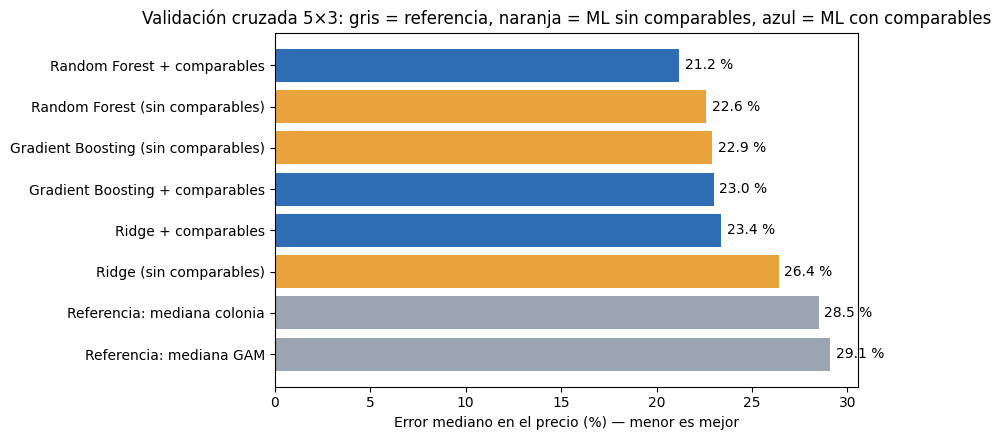

In [63]:
fig, ax = plt.subplots(figsize=(9, 4.5))
t = tabla.sort_values("Error mediano %", ascending=False)
colores = ["#9aa5b1" if "Referencia" in i else "#e8a33d" if "sin" in i else "#2f6db5" for i in t.index]
ax.barh(t.index, t["Error mediano %"], color=colores)
for i, v in enumerate(t["Error mediano %"]):
    ax.text(v + 0.3, i, f"{v:.1f} %", va="center")
ax.set_xlabel("Error mediano en el precio (%) — menor es mejor")
ax.set_title("Validación cruzada 5×3: gris = referencia, naranja = ML sin comparables, azul = ML con comparables")
plt.tight_layout(); plt.show()

### 5.2 Modelo elegido: ¿dónde falla?

In [64]:
mejor = tabla.drop([i for i in tabla.index if "Referencia" in i]).index[0]
print("Modelo elegido:", mejor)
pred_log = oof[mejor]
err = (np.exp(pred_log) * m2 - precio_real) / precio_real
analisis = df.assign(pred_precio=np.exp(pred_log) * m2, error_pct=100 * err, error_abs_pct=100 * np.abs(err))

n_col = analisis["colonia"].map(analisis["colonia"].value_counts()).fillna(0)
analisis["datos_en_colonia"] = pd.cut(n_col, [0, 2, 7, 1000], labels=["1–2 casas", "3–7 casas", "8+ casas"])
print("\nError según cuántas casas hay en la colonia:")
print(analisis.groupby("datos_en_colonia", observed=True)["error_abs_pct"]
      .agg(casas="size", error_mediano="median", dentro_25=lambda e: (e <= 25).mean() * 100).round(1))

analisis["rango_precio"] = pd.qcut(analisis["precio"], 4, labels=["barata", "media-baja", "media-alta", "cara"])
print("\nSesgo por rango de precio (positivo = el modelo sobreestima):")
print(analisis.groupby("rango_precio", observed=True)["error_pct"].agg(["median", "size"]).round(1))

print("\nError por tipo (ojo: sólo hay 3 departamentos, su error no es representativo):")
print(analisis.groupby("tipo")["error_abs_pct"].agg(["median", "size"]).round(1))

Modelo elegido: Random Forest + comparables

Error según cuántas casas hay en la colonia:
                  casas  error_mediano  dentro_25
datos_en_colonia                                 
1–2 casas            79           24.1       51.9
3–7 casas           143           20.8       58.7
8+ casas            281           20.3       57.3

Sesgo por rango de precio (positivo = el modelo sobreestima):
              median  size
rango_precio              
barata          33.4   128
media-baja      -3.6   127
media-alta      -9.1   124
cara           -12.2   127

Error por tipo (ojo: sólo hay 3 departamentos, su error no es representativo):
                             median  size
tipo                                     
casa                           20.8   484
departamento                   64.5     3
edificio / varias viviendas    28.7    19


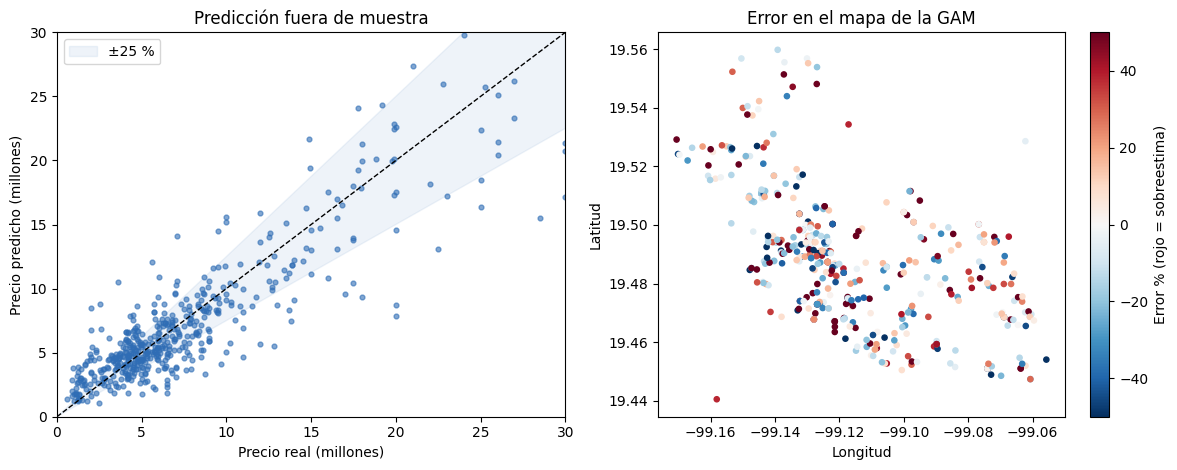

In [65]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
ax[0].scatter(precio_real / 1e6, analisis["pred_precio"] / 1e6, s=12, alpha=0.6, color="#2f6db5")
lim = [0, np.percentile(precio_real / 1e6, 99)]
ax[0].plot(lim, lim, "k--", lw=1)
ax[0].fill_between(lim, [l * 0.75 for l in lim], [l * 1.25 for l in lim], color="#2f6db5", alpha=0.08, label="±25 %")
ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel("Precio real (millones)"); ax[0].set_ylabel("Precio predicho (millones)")
ax[0].set_title("Predicción fuera de muestra"); ax[0].legend()

sc = ax[1].scatter(analisis["lon"], analisis["lat"], c=analisis["error_pct"].clip(-50, 50), cmap="RdBu_r", s=14)
plt.colorbar(sc, ax=ax[1], label="Error % (rojo = sobreestima)")
ax[1].set_title("Error en el mapa de la GAM"); ax[1].set_xlabel("Longitud"); ax[1].set_ylabel("Latitud")
plt.tight_layout(); plt.show()

### 5.3 Colonias que el modelo nunca vio (GroupKFold por colonia)

In [66]:
grupos = df["colonia"].fillna("sin colonia").values
duro = []
for nombre in ["Referencia: mediana GAM", mejor.replace(" + comparables", " (sin comparables)"), mejor]:
    p = predecir_oof(candidatos[nombre], X, y, GroupKFold(5), grupos)
    r = pd.Series(metricas(precio_real, np.exp(p) * m2, y, p), name=nombre)
    duro.append(r)
pd.DataFrame(duro).round(1)

,MAPE %,Error mediano %,Dentro ±15 %,Dentro ±25 %,MAE (millones),R² log(p/m²)
Referencia: mediana GAM,41.3,29.1,24.3,42.9,2.8,-0.0
Random Forest (sin comparables),34.7,26.2,31.2,48.4,2.2,0.2
Random Forest + comparables,34.9,27.2,26.7,45.1,2.5,0.0


### 5.4 Importancia de variables (permutación)

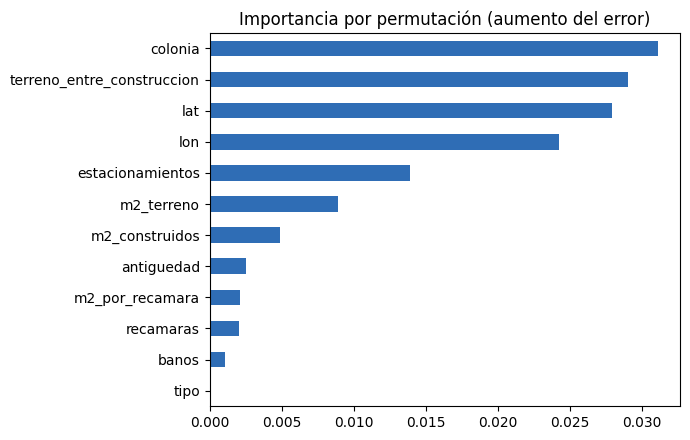

Nota: 'colonia', 'lat' y 'lon' incluyen el efecto de las variables de comparables que se calculan con ellas.


In [67]:
tr, te = next(KFold(5, shuffle=True, random_state=0).split(X))
m = clone(candidatos[mejor]).fit(X.iloc[tr], y[tr])
imp = permutation_importance(m, X.iloc[te], y[te], n_repeats=20, random_state=0, scoring="neg_mean_absolute_error")
importancia = pd.Series(imp.importances_mean, index=X.columns).sort_values()
importancia.plot.barh(figsize=(7, 4.5), color="#2f6db5", title="Importancia por permutación (aumento del error)")
plt.tight_layout(); plt.show()
print("Nota: 'colonia', 'lat' y 'lon' incluyen el efecto de las variables de comparables que se calculan con ellas.")

### 5.5 Rango de confianza del 80 %

In [68]:
residuos = y - pred_log
q_bajo, q_alto = np.quantile(residuos, [0.10, 0.90])
cobertura = ((precio_real >= np.exp(pred_log + q_bajo) * m2) & (precio_real <= np.exp(pred_log + q_alto) * m2)).mean()
print(f"Rango del 80 %: de {100 * (np.exp(q_bajo) - 1):+.0f} % a {100 * (np.exp(q_alto) - 1):+.0f} % alrededor de la predicción")
print(f"Cobertura real en validación: {100 * cobertura:.0f} %")

Rango del 80 %: de -36 % a +57 % alrededor de la predicción
Cobertura real en validación: 80 %


### 5.6 Criterios de éxito

In [69]:
ref = tabla.loc[[i for i in tabla.index if "Referencia" in i], "Error mediano %"].min()
gan = tabla.loc[mejor, "Error mediano %"]
print(f"1. Supera a las referencias sin ML: {gan:.1f} % vs {ref:.1f} % de error mediano  ->",
      "✔" if gan < ref - 3 else "✘")
print(f"2. Error mediano ≈ 20 % o menos: {gan:.1f} %  ->",
      "✔" if gan <= 20 else "parcial (cerca de la meta)" if gan <= 23 else "✘")
print(f"3. Rango del 80 % calibrado: cubre {100 * cobertura:.0f} % de las casas  ->",
      "✔" if abs(cobertura - 0.8) < 0.05 else "✘")
print(f"\nComparación de orden de magnitud: precio mediano del dataset ${datos['precio'].median():,.0f}.")
print("Como referencia, la SHF reportó un precio promedio de $4,285,135 para toda la CDMX en el 2.º trimestre de 2026")
print("(viviendas con crédito hipotecario, incluye departamentos). El dataset es más caro porque predominan casas grandes de la zona de Lindavista.")

1. Supera a las referencias sin ML: 21.2 % vs 28.5 % de error mediano  -> ✔
2. Error mediano ≈ 20 % o menos: 21.2 %  -> parcial (cerca de la meta)
3. Rango del 80 % calibrado: cubre 80 % de las casas  -> ✔

Comparación de orden de magnitud: precio mediano del dataset $5,950,000.
Como referencia, la SHF reportó un precio promedio de $4,285,135 para toda la CDMX en el 2.º trimestre de 2026
(viviendas con crédito hipotecario, incluye departamentos). El dataset es más caro porque predominan casas grandes de la zona de Lindavista.


---
# FASE 6 · Despliegue

### 6.1 Modelo final
Se entrena con todas las casas. Entrada: colonia y m² construidos; opcionales: m² de superficie, recámaras, baños, estacionamientos, antigüedad y coordenadas (Google Maps → clic derecho). Salida: precio, rango del 80 % y nivel de confianza.

In [70]:
modelo_final = clone(candidatos[mejor]).fit(X, y)

colonias_conocidas = df.dropna(subset=["colonia"]).groupby("colonia").agg(
    lat=("lat", "median"), lon=("lon", "median"), casas=("colonia", "size"))
llaves = {llave(c): c for c in colonias_conocidas.index}


def predecir_casa(colonia, m2_construidos, m2_terreno=None, recamaras=None, banos=None,
                  estacionamientos=None, antiguedad=None, lat=None, lon=None, tipo="casa"):
    k = llave(colonia)
    parecida = difflib.get_close_matches(k, llaves.keys(), n=1, cutoff=0.75)
    col = llaves[parecida[0]] if parecida else colonia
    if lat is None and parecida:
        lat, lon = colonias_conocidas.loc[col, ["lat", "lon"]]
    fila = pd.DataFrame([{
        "m2_construidos": m2_construidos, "m2_terreno": m2_terreno, "recamaras": recamaras, "banos": banos,
        "estacionamientos": estacionamientos, "antiguedad": antiguedad, "lat": lat, "lon": lon,
        "tipo": tipo, "colonia": col}]).astype({"m2_terreno": float, "recamaras": float, "banos": float,
                                                "estacionamientos": float, "antiguedad": float,
                                                "lat": float, "lon": float})
    fila["terreno_entre_construccion"] = fila["m2_terreno"] / fila["m2_construidos"]
    fila["m2_por_recamara"] = fila["m2_construidos"] / fila["recamaras"]
    p = modelo_final.predict(fila[X.columns])[0]

    comp = modelo_final.named_steps["prep"].named_transformers_["comparables"].transform(fila[COMPARABLES_IN])[0]
    casas_col, dist_km = comp[1], comp[3]
    avisos = []
    if not parecida:
        avisos.append("colonia sin datos")
    if casas_col < 3:
        avisos.append(f"solo {int(casas_col)} casa(s) en la colonia")
    if np.isnan(dist_km):
        avisos.append("sin coordenadas")
    elif dist_km > 1.2:
        avisos.append(f"comparables lejos ({dist_km:.1f} km en promedio)")
    return {
        "colonia_usada": col,
        "precio_m2": round(np.exp(p)),
        "precio_estimado": round(np.exp(p) * m2_construidos, -3),
        "rango_80%": (round(np.exp(p + q_bajo) * m2_construidos, -3), round(np.exp(p + q_alto) * m2_construidos, -3)),
        "confianza": "baja: " + "; ".join(avisos) if avisos else "normal",
    }

### 6.2 Casas a valuar
Reemplaza los ejemplos por las casas del profe; lo que no se sepa se deja en `None`.

In [71]:
casas_profe = [
    dict(colonia="Lindavista Sur", m2_construidos=258, m2_terreno=242, recamaras=7,
         estacionamientos=3, antiguedad=16, lat=19.4858129, lon=-99.1280726),
    dict(colonia="San Juan de Aragón", m2_construidos=150, m2_terreno=120, recamaras=3, banos=2),
    dict(colonia="Cuautepec Barrio Alto", m2_construidos=120, recamaras=3, banos=1, lat=19.48600505400475, lon=-99.12811551975172),
]

salida = pd.DataFrame([{**c, **predecir_casa(**c)} for c in casas_profe])
salida["precio_estimado"] = salida["precio_estimado"].map("${:,.0f}".format)
salida["rango_80%"] = salida["rango_80%"].map(lambda r: f"${r[0]:,.0f} – ${r[1]:,.0f}")
salida[["colonia", "colonia_usada", "m2_construidos", "precio_m2", "precio_estimado", "rango_80%", "confianza"]]

,colonia,colonia_usada,m2_construidos,precio_m2,precio_estimado,rango_80%,confianza
0,Lindavista Sur,Lindavista Sur,258,34048,"$8,784,000","$5,606,000 – $13,799,000",normal
1,San Juan de Aragón,San Juan de Aragón,150,22307,"$3,346,000","$2,135,000 – $5,256,000",normal
2,Cuautepec Barrio Alto,Cuautepec Barrio Alto,120,28227,"$3,387,000","$2,162,000 – $5,321,000",baja: solo 2 casa(s) en la colonia


### 6.3 Mantenimiento
- Repetir la recolección y la limpieza cada trimestre y reentrenar.
- Revisar que el rango del 80 % siga cubriendo al 80 %.
- Mejoras: variables de zona (INEGI, distancia al Metro) y el estado de la casa desde el texto del anuncio.

### 6.4 Guardar resultados

In [72]:
tabla.to_csv("comparacion_modelos.csv", encoding="utf-8-sig")
try:
    from google.colab import files
    for f in ["casas_gam_limpio.csv", "casas_gam_excluidas.csv", "resumen_limpieza.csv", "comparacion_modelos.csv"]:
        files.download(f)
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Conclusiones
- No hay datos públicos de compraventa por casa, así que se usaron anuncios de tres portales, respetando los bloqueos y sin datos personales.
- La mayoría de los anuncios baratos eran **remates**; se excluyeron junto con duplicados, ubicaciones falsas y errores, dejando registro de cada exclusión.
- El **Random Forest con comparables** fue el mejor modelo y superó claramente a las referencias sin ML.
- **Limitaciones:** precios de oferta, pocas casas en zonas populares (rango más ancho), sesgo hacia el promedio y falta del estado de la casa en los anuncios.